# Flooded Area Mapping from Sentinel-1 Satellite Images
**Individual project | Sen1Floods11 v1.1 | Google Colab / Kaggle**

Comparison: **SAR VH threshold baseline**, **compact U-Net trained from scratch**, and **ResNet18 encoder U-Net with ImageNet pretraining**. Outputs include pixel-level IoU, Dice, confusion matrices, classification reports, loss/accuracy curves, overlays, and reproducible model comparison.

Dataset: [Official Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11). Its `LabelHand` masks identify **water (1)**, **non-water (0)** and **invalid (-1)**; masks alone cannot distinguish new floodwater from permanent water. The report must describe this as *water/flood inundation mapping* and acknowledge this limitation. The dataset has **446 hand-labelled 512×512 chips**. Do not claim these are all flooded.

**Run with GPU:** Colab: Runtime → Change runtime type → T4 GPU. Kaggle: Settings → Accelerator → GPU **and Internet → On** (needed for the dataset download). Then Run all. Download ~700 MB (plus pretrained weights) and training may take time. Adjust `EPOCHS` as appropriate and report actual settings/results.

In [78]:
%pip -q install rasterio scikit-learn segmentation-models-pytorch pandas matplotlib tqdm google-cloud-storage

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration and reproducibility

In [79]:
import os, re, csv, gc, random, json, shutil, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rasterio
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm
import segmentation_models_pytorch as smp
from google.cloud import storage

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# Works on Kaggle, Colab or locally
if Path('/kaggle/working').exists(): ROOT = Path('/kaggle/working/flood_mapping')
elif Path('/content').exists():      ROOT = Path('/content/flood_mapping')
else:                                ROOT = Path('./flood_mapping')
DATA = ROOT/'data'; OUT = ROOT/'outputs'; OUT.mkdir(parents=True, exist_ok=True)
SIZE=256; BATCH_SIZE=8; EPOCHS=30; LR=3e-4
# Fixed SAR dB range used for normalisation (VV/VH are already in dB in Sen1Floods11)
DB_MIN, DB_MAX = -35., 5.
print('Device:', DEVICE, '| Output:', OUT)

Device: cuda | Output: /kaggle/working/flood_mapping/outputs


## 2. Download public hand-labelled imagery and official splits

Uses public anonymous Google Cloud Storage reads; no personal API key needed. The original imagery is **2-band SAR (VV, VH)**, not RGB. We use public `gs://sen1floods11/v1.1/...` files without downloading the weak labels or Sentinel-2 bands.

In [80]:
BUCKET='sen1floods11'
PREFIX='v1.1/data/flood_events/HandLabeled/'
client = storage.Client.create_anonymous_client()
bucket=client.bucket(BUCKET)
def download_prefix(prefix, directory):
    directory.mkdir(parents=True,exist_ok=True)
    blobs=list(client.list_blobs(BUCKET,prefix=prefix))
    files=[x for x in blobs if x.name.lower().endswith(('.tif','.csv'))]
    print('Found',len(files),'files in',prefix)
    if not files: raise RuntimeError('No objects found; check cloud bucket access/path.')
    for x in tqdm(files,desc=directory.name):
        dest=directory/Path(x.name).name
        if not dest.exists() or dest.stat().st_size != x.size:
            x.download_to_filename(str(dest))
    return files

split_files=download_prefix('v1.1/splits/flood_handlabeled/',DATA/'splits')
image_files=download_prefix(PREFIX+'S1Hand/',DATA/'S1Hand')
mask_files=download_prefix(PREFIX+'LabelHand/',DATA/'LabelHand')
print('Downloaded imagery:',len(image_files),'masks:',len(mask_files))

Found 4 files in v1.1/splits/flood_handlabeled/


splits:   0%|          | 0/4 [00:00<?, ?it/s]

Found 446 files in v1.1/data/flood_events/HandLabeled/S1Hand/


S1Hand:   0%|          | 0/446 [00:00<?, ?it/s]

Found 446 files in v1.1/data/flood_events/HandLabeled/LabelHand/


LabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

Downloaded imagery: 446 masks: 446


## 3. Read official train / validation / test splits; check image–mask pairing

In [81]:
print('Official CSVs:',[p.name for p in (DATA/'splits').glob('*.csv')])
for f in sorted((DATA/'splits').glob('*.csv')):
    print('\n',f.name, '\n',f.read_text().splitlines()[:3])

# Official split rows often include full filenames. Match by image filename or chip identity.
def core_id(path_or_name):
    name=Path(str(path_or_name)).stem
    return re.sub(r'_(S1Hand|LabelHand|S2Hand)$','',name,flags=re.I)
images={core_id(p):p for p in (DATA/'S1Hand').glob('*.tif')}
masks={core_id(p):p for p in (DATA/'LabelHand').glob('*.tif')}
paired={k:(images[k],masks[k]) for k in images.keys()&masks.keys()}
print('Pairs found:',len(paired))
assert len(paired)>0,'Image/mask pairing failed.'

def get_split_file(split):
    names={'train':['flood_train_data.csv','train.csv'], 'valid':['flood_valid_data.csv','val.csv','valid.csv'], 'test':['flood_test_data.csv','test.csv']}
    paths=list((DATA/'splits').glob('*.csv'))
    for pattern in names[split]:
        p=next((p for p in paths if p.name.lower()==pattern),None)
        if p:return p
    p=next((p for p in paths if split in p.name.lower()),None)
    if p:return p
    raise FileNotFoundError('Missing official '+split+' CSV in '+str(paths))

def read_pairs(split):
    p=get_split_file(split)
    selected=[]; seen=set()
    with p.open(newline='') as fh:
        rows=list(csv.reader(fh))
    for row in rows:
        keys={core_id(v) for v in row if isinstance(v,str) and v.lower().strip().endswith('.tif')}
        # Rows might include extra metadata / no extension. Search for an explicit chip ID if needed.
        if not keys:
            raw=' '.join(row)
            keys={k for k in paired if k in raw}
        for k in sorted(keys):
            if k in paired and k not in seen:
                seen.add(k); selected.append(paired[k])
    if not selected:
        raise ValueError('Could not parse '+str(p)+'; inspect printed CSV rows and adapt parser.')
    return selected

splits={x:read_pairs(x) for x in ('train','valid','test')}
ids={s:{core_id(im) for im,_ in pairs} for s,pairs in splits.items()}
assert not (ids['train']&ids['valid'] or ids['train']&ids['test'] or ids['valid']&ids['test']),'Overlapping split IDs!'
print({s:len(v) for s,v in splits.items()})
assert sum(map(len,splits.values()))<=len(paired)
pd.DataFrame({'split':list(splits),'image_count':[len(splits[s]) for s in splits]}).to_csv(OUT/'split_counts.csv',index=False)

Official CSVs: ['flood_test_data.csv', 'flood_train_data.csv', 'flood_bolivia_data.csv', 'flood_valid_data.csv']

 flood_bolivia_data.csv 
 ['Bolivia_103757_S1Hand.tif,Bolivia_103757_LabelHand.tif', 'Bolivia_129334_S1Hand.tif,Bolivia_129334_LabelHand.tif', 'Bolivia_195474_S1Hand.tif,Bolivia_195474_LabelHand.tif']

 flood_test_data.csv 
 ['Ghana_313799_S1Hand.tif,Ghana_313799_LabelHand.tif', 'Ghana_1078550_S1Hand.tif,Ghana_1078550_LabelHand.tif', 'Ghana_97059_S1Hand.tif,Ghana_97059_LabelHand.tif']

 flood_train_data.csv 
 ['Ghana_103272_S1Hand.tif,Ghana_103272_LabelHand.tif', 'Ghana_24858_S1Hand.tif,Ghana_24858_LabelHand.tif', 'Ghana_147015_S1Hand.tif,Ghana_147015_LabelHand.tif']

 flood_valid_data.csv 
 ['Ghana_5079_S1Hand.tif,Ghana_5079_LabelHand.tif', 'Ghana_895194_S1Hand.tif,Ghana_895194_LabelHand.tif', 'Ghana_868803_S1Hand.tif,Ghana_868803_LabelHand.tif']
Pairs found: 446
{'train': 252, 'valid': 89, 'test': 90}


## 4. Dataset preprocessing, augmentation and class distribution

`-1` is **ignored**, not treated as non-water. Images use a documented fixed SAR dB clipping range (-35 to +5 dB), with bilinear resizing. **All chips are read and resized once and cached in memory** (≈230 MB), so no DataLoader worker processes are needed. Masks use **nearest neighbor** to preserve class IDs. Train-only horizontal/vertical flipping and 90° rotations keep the image and label aligned.

Load train:   0%|          | 0/252 [00:00<?, ?it/s]

Load valid:   0%|          | 0/89 [00:00<?, ?it/s]

Load test:   0%|          | 0/90 [00:00<?, ?it/s]

Train pixel counts, non-water, water, invalid: [12963114  1362418  2189540]


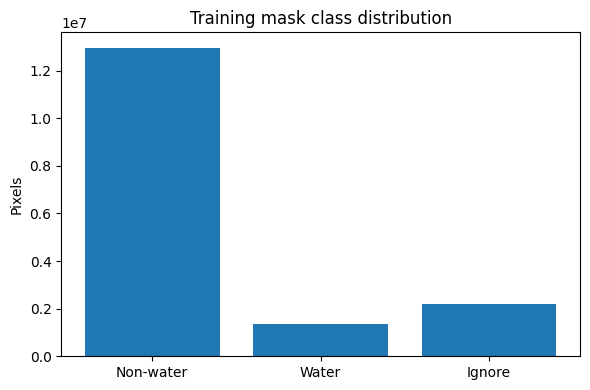

In [82]:
def load_chip(ip,mp):
    with rasterio.open(ip) as f: image=f.read()[:2].astype('float32')
    with rasterio.open(mp) as f: mask=f.read(1).astype('int16')
    image=np.nan_to_num(image,nan=DB_MIN,posinf=DB_MAX,neginf=DB_MIN)
    image=(np.clip(image,DB_MIN,DB_MAX)-DB_MIN)/(DB_MAX-DB_MIN)
    x=torch.from_numpy(image).float()[None]
    y=torch.from_numpy(mask.astype('float32'))[None,None]
    x=F.interpolate(x,size=(SIZE,SIZE),mode='bilinear',align_corners=False,antialias=True)[0]
    y=F.interpolate(y,size=(SIZE,SIZE),mode='nearest')[0,0].to(torch.int8)   # nearest keeps -1/0/1
    return x,y

class FloodDataset(Dataset):
    """Reads every chip once; __getitem__ then only does cheap tensor ops (no worker processes needed)."""
    def __init__(self,pairs,augment=False,desc=''):
        xs,ys=zip(*[load_chip(ip,mp) for ip,mp in tqdm(pairs,desc=desc,leave=False)])
        self.x=torch.stack(xs); self.y=torch.stack(ys); self.augment=augment
    def __len__(self):return len(self.x)
    def __getitem__(self,idx):
        x,y=self.x[idx],self.y[idx].long()
        if self.augment:
            if random.random()<.5: x=x.flip(-1); y=y.flip(-1)
            if random.random()<.5: x=x.flip(-2); y=y.flip(-2)
            k=random.randrange(4); x=torch.rot90(x,k,(-2,-1)); y=torch.rot90(y,k,(-2,-1))
        return x.contiguous(),y.contiguous()

train_ds=FloodDataset(splits['train'],True,'Load train')
val_ds=FloodDataset(splits['valid'],False,'Load valid')
test_ds=FloodDataset(splits['test'],False,'Load test')
g=torch.Generator(); g.manual_seed(SEED)
# num_workers=0 on purpose: data is already in RAM, and this avoids the
# "AssertionError: can only test a child process" DataLoader worker errors.
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,generator=g,drop_last=False)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)

yt=train_ds.y
counts=np.array([int((yt==0).sum()),int((yt==1).sum()),int((yt==-1).sum())],dtype='int64')
print('Train pixel counts, non-water, water, invalid:',counts)
pd.DataFrame({'label':['Non-water','Water','Ignore (-1)'],'pixels':counts}).to_csv(OUT/'class_distribution.csv',index=False)
plt.figure(figsize=(6,4));plt.bar(['Non-water','Water','Ignore'],counts);plt.ylabel('Pixels');plt.title('Training mask class distribution');plt.tight_layout();plt.savefig(OUT/'class_distribution.png',dpi=180);plt.show()

## 5. Show SAR input and ground truth

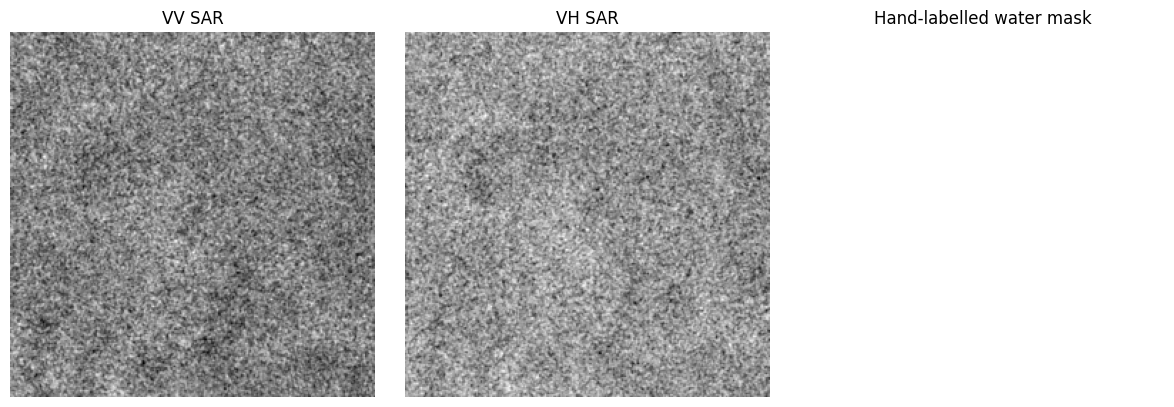

In [83]:
x,y=val_ds[0]
fig,axs=plt.subplots(1,3,figsize=(12,4))
axs[0].imshow(x[0],cmap='gray');axs[0].set_title('VV SAR')
axs[1].imshow(x[1],cmap='gray');axs[1].set_title('VH SAR')
axs[2].imshow(np.ma.masked_where(y.numpy()==-1,y.numpy()),vmin=0,vmax=1,cmap='Blues');axs[2].set_title('Hand-labelled water mask')
for a in axs:a.axis('off')
plt.tight_layout();plt.savefig(OUT/'sample_dataset.png',dpi=180);plt.show()

## 6. Compact CNN and pretrained transfer learning model

In [84]:
# Same U-Net decoder family; encoder varies from scratch to ImageNet-pretrained.
# The pretrained network accepts two SAR bands via segmentation_models_pytorch input-channel adaptation.
def make_model(name):
    seed_everything()   # identical decoder init / ordering for a fair comparison
    return smp.Unet(encoder_name='resnet18',encoder_weights=('imagenet' if name=='transfer_unet' else None),
                    in_channels=2,classes=1,encoder_depth=4,decoder_channels=(128,64,32,16))
models={name:make_model(name) for name in ('compact_unet','transfer_unet')}
for name,model in models.items():
    print(name,'parameters:',sum(p.numel() for p in model.parameters()))

# Mask -1 pixels out of loss and metrics. BCE + soft Dice: water is only ~10% of pixels, and Dice
# directly optimises the overlap metric (IoU/Dice) we report.
def loss_fn(logits,target):
    good=(target!=-1)
    if not good.any(): return logits.sum()*0
    truth=(target==1).float()
    lg=logits[:,0]
    bce=F.binary_cross_entropy_with_logits(lg,truth,reduction='none')[good].mean()
    p=torch.sigmoid(lg)*good; t=truth*good
    dice=1-(2*(p*t).sum()+1)/(p.sum()+t.sum()+1)
    return bce+dice

def accumulate_confusion(logits,y):
    pred=(torch.sigmoid(logits[:,0])>=.5)
    valid=(y!=-1)
    truth=(y==1)
    return np.array([int(((~pred)&(~truth)&valid).sum()),int((pred&(~truth)&valid).sum()),int(((~pred)&truth&valid).sum()),int((pred&truth&valid).sum())],dtype=np.int64)

def scores(c):
    tn,fp,fn,tp=map(int,c)
    safe=lambda n,d: n/d if d else 0.
    return {'accuracy':safe(tp+tn,tp+tn+fp+fn),'precision':safe(tp,tp+fp),'recall':safe(tp,tp+fn),
            'f1_dice':safe(2*tp,2*tp+fp+fn),'iou':safe(tp,tp+fp+fn),'tn':tn,'fp':fp,'fn':fn,'tp':tp}

def run_epoch(model,loader,optimizer=None):
    training=optimizer is not None
    model.train(training)
    losses=[]; conf=np.zeros(4,dtype=np.int64)
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits=model(x); loss=loss_fn(logits,y)
            if training:
                optimizer.zero_grad(set_to_none=True);loss.backward();optimizer.step()
        losses.append(loss.item());conf+=accumulate_confusion(logits.detach(),y)
    return float(np.mean(losses)),scores(conf)

compact_unet parameters: 11964753
transfer_unet parameters: 11964753


## 7. Train both networks; save best validation-IoU weights and curves


Training: compact_unet
compact_unet epoch 1/30: train loss 1.3184, val loss 1.2093, val IoU 0.0093, val Dice 0.0183
compact_unet epoch 2/30: train loss 1.0373, val loss 0.8401, val IoU 0.5765, val Dice 0.7314
compact_unet epoch 3/30: train loss 0.8776, val loss 0.8079, val IoU 0.5657, val Dice 0.7226
compact_unet epoch 4/30: train loss 0.8109, val loss 0.6968, val IoU 0.5782, val Dice 0.7327
compact_unet epoch 5/30: train loss 0.7382, val loss 0.6118, val IoU 0.6077, val Dice 0.7560
compact_unet epoch 6/30: train loss 0.6976, val loss 0.6500, val IoU 0.5925, val Dice 0.7441
compact_unet epoch 7/30: train loss 0.7012, val loss 0.6036, val IoU 0.5738, val Dice 0.7292
compact_unet epoch 8/30: train loss 0.6659, val loss 0.5754, val IoU 0.5951, val Dice 0.7462
compact_unet epoch 9/30: train loss 0.6066, val loss 0.5394, val IoU 0.5942, val Dice 0.7455
compact_unet epoch 10/30: train loss 0.6254, val loss 0.5389, val IoU 0.5987, val Dice 0.7489
compact_unet epoch 11/30: train loss 0.6281, 

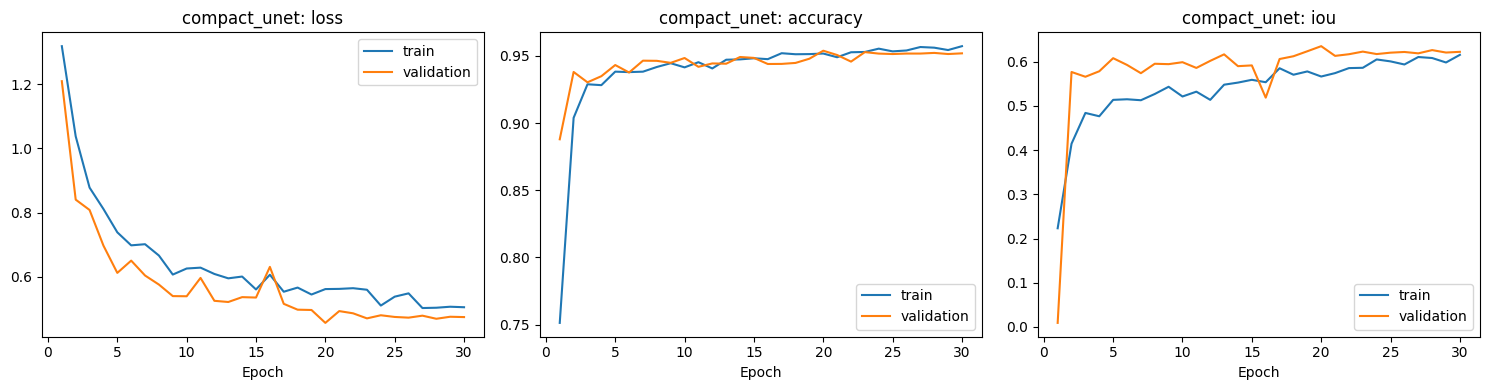


Training: transfer_unet
transfer_unet epoch 1/30: train loss 1.1844, val loss 0.9032, val IoU 0.5344, val Dice 0.6966
transfer_unet epoch 2/30: train loss 0.9366, val loss 0.8275, val IoU 0.5158, val Dice 0.6806
transfer_unet epoch 3/30: train loss 0.7957, val loss 0.7096, val IoU 0.5774, val Dice 0.7321
transfer_unet epoch 4/30: train loss 0.7419, val loss 0.6467, val IoU 0.5974, val Dice 0.7480
transfer_unet epoch 5/30: train loss 0.6856, val loss 0.6578, val IoU 0.5581, val Dice 0.7164
transfer_unet epoch 6/30: train loss 0.6276, val loss 0.5657, val IoU 0.5914, val Dice 0.7432
transfer_unet epoch 7/30: train loss 0.6477, val loss 0.5712, val IoU 0.5902, val Dice 0.7423
transfer_unet epoch 8/30: train loss 0.6049, val loss 0.5668, val IoU 0.5791, val Dice 0.7334
transfer_unet epoch 9/30: train loss 0.5417, val loss 0.4992, val IoU 0.6106, val Dice 0.7582
transfer_unet epoch 10/30: train loss 0.5811, val loss 0.5278, val IoU 0.6054, val Dice 0.7542
transfer_unet epoch 11/30: train l

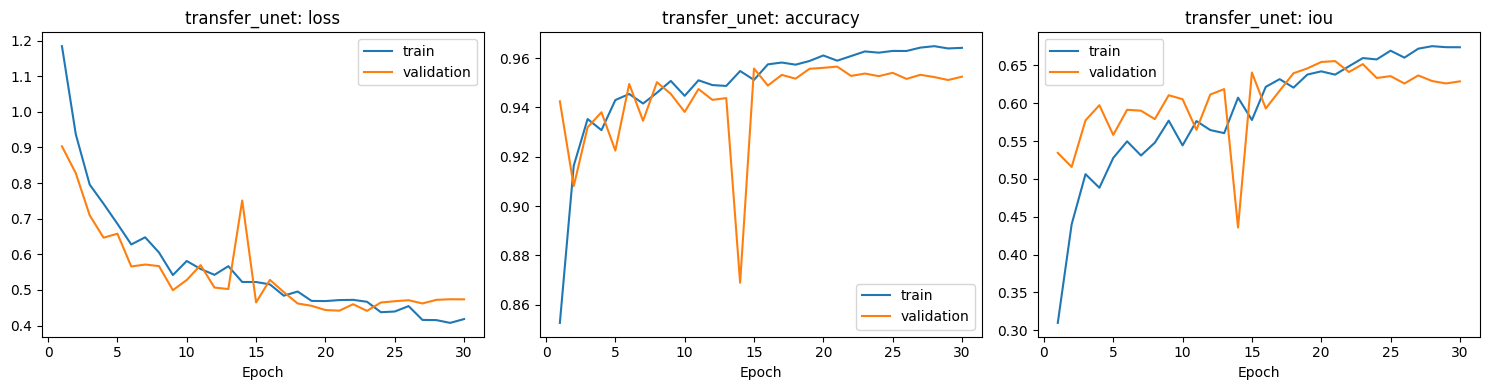

In [85]:
histories={}
for name,model in models.items():
    print('\nTraining:',name)
    model=model.to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS)
    seed_everything()   # same data order/augmentation stream for both models
    g.manual_seed(SEED)
    best=-1.; history=[]
    for epoch in range(1,EPOCHS+1):
        tr_loss,tr=run_epoch(model,train_loader,optimizer)
        vl_loss,vl=run_epoch(model,val_loader)
        scheduler.step()
        history.append({'epoch':epoch,'train_loss':tr_loss,'val_loss':vl_loss,'train_accuracy':tr['accuracy'],'val_accuracy':vl['accuracy'],'train_iou':tr['iou'],'val_iou':vl['iou']})
        print(f'{name} epoch {epoch}/{EPOCHS}: train loss {tr_loss:.4f}, val loss {vl_loss:.4f}, val IoU {vl["iou"]:.4f}, val Dice {vl["f1_dice"]:.4f}')
        if vl['iou']>best:
            best=vl['iou']; torch.save(model.state_dict(),OUT/f'{name}_best.pth')
    histories[name]=pd.DataFrame(history)
    histories[name].to_csv(OUT/f'{name}_history.csv',index=False)
    fig,ax=plt.subplots(1,3,figsize=(15,4))
    for j,key in enumerate(['loss','accuracy','iou']):
        ax[j].plot(histories[name]['epoch'],histories[name]['train_'+key],label='train')
        ax[j].plot(histories[name]['epoch'],histories[name]['val_'+key],label='validation')
        ax[j].set_title(f'{name}: {key}');ax[j].set_xlabel('Epoch');ax[j].legend()
    plt.tight_layout();plt.savefig(OUT/f'{name}_curves.png',dpi=180);plt.show()
    model.cpu();gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

## 8. SAR threshold baseline (tuned ONLY using validation set)

Water often exhibits low backscatter in Sentinel-1 SAR imagery. The threshold is learned only on the validation partition. Evaluate the selected threshold on the untouched test set. This is a **simple low-VH threshold**, not NDWI (which requires optical bands).

Validation-selected normalized VH threshold: 0.3 (= -23.0 dB) | validation IoU: 0.5272480820955369


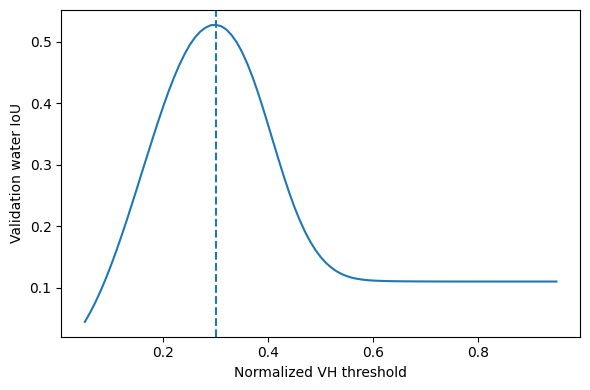

In [86]:
# Use normalized VH, second channel, for comparison (smaller value -> predicted water).
def threshold_conf(dataset,t):
    vh=dataset.x[:,1]; gt=dataset.y
    pred=vh<t; good=gt!=-1; truth=gt==1
    return np.array([int((~pred&~truth&good).sum()),int((pred&~truth&good).sum()),
                     int((~pred&truth&good).sum()),int((pred&truth&good).sum())],dtype=np.int64)
thresholds=np.linspace(.05,.95,91)
val_search=[(float(t),scores(threshold_conf(val_ds,float(t)))['iou']) for t in thresholds]
best_threshold,max_iou=max(val_search,key=lambda row:row[1])
print('Validation-selected normalized VH threshold:',best_threshold,
      '(= %.1f dB)'%(best_threshold*(DB_MAX-DB_MIN)+DB_MIN),'| validation IoU:',max_iou)
plt.figure(figsize=(6,4));plt.plot([p[0] for p in val_search],[p[1] for p in val_search]);plt.axvline(best_threshold,ls='--');plt.xlabel('Normalized VH threshold');plt.ylabel('Validation water IoU');plt.tight_layout();plt.savefig(OUT/'baseline_threshold_tuning.png',dpi=180);plt.show()

## 9. Held-out test comparison, pixel-level confusion matrices and classification reports

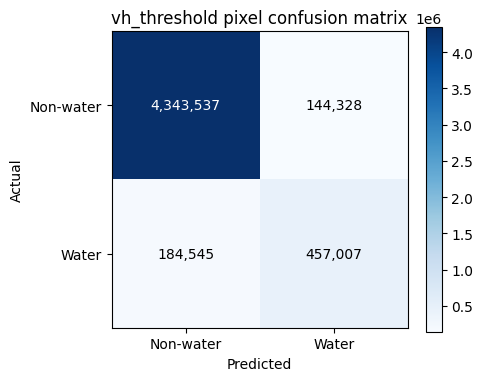

vh_threshold 
            precision    recall    support  f1-score
Non-water   0.959244  0.967840  4487865.0  0.963523
Water       0.759987  0.712346   641552.0  0.735396


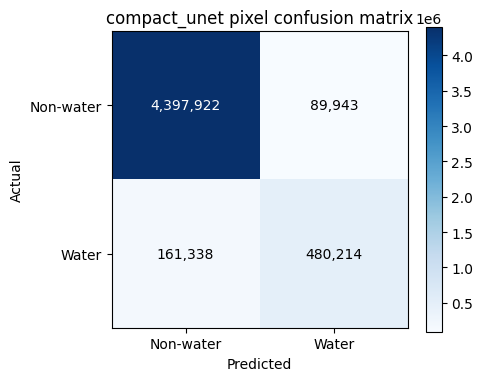

compact_unet 
            precision    recall    support  f1-score
Non-water   0.964613  0.979959  4487865.0  0.972225
Water       0.842249  0.748519   641552.0  0.792623


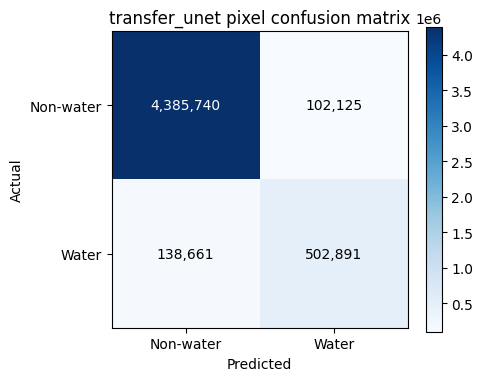

transfer_unet 
            precision    recall    support  f1-score
Non-water   0.969353  0.977244  4487865.0  0.973282
Water       0.831203  0.783866   641552.0  0.806841


,model,iou,f1_dice,accuracy,precision,recall
2,transfer_unet,0.676222,0.806841,0.953058,0.831203,0.783866
1,compact_unet,0.656483,0.792623,0.951012,0.842249,0.748519
0,vh_threshold,0.581523,0.735396,0.935885,0.759987,0.712346


All metrics are computed on the held-out test set only.


In [87]:
def eval_network(model,loader):
    conf=np.zeros(4,dtype=np.int64)
    model.eval()
    with torch.no_grad():
        for x,y in loader:
            conf+=accumulate_confusion(model(x.to(DEVICE)),y.to(DEVICE))
    return conf

all_conf={'vh_threshold':threshold_conf(test_ds,best_threshold)}
for name,model in models.items():
    model.load_state_dict(torch.load(OUT/f'{name}_best.pth',map_location='cpu',weights_only=True))
    model.to(DEVICE)
    all_conf[name]=eval_network(model,test_loader)
    model.cpu()
    if torch.cuda.is_available():torch.cuda.empty_cache()
rows=[]
for name,c in all_conf.items():
    s=scores(c);rows.append({'model':name,**s})
    mat=np.array([[s['tn'],s['fp']],[s['fn'],s['tp']]])
    fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(mat,cmap='Blues')
    for (i,j),v in np.ndenumerate(mat):ax.text(j,i,f'{v:,}',ha='center',va='center',color='white' if v>mat.max()/2 else 'black')
    ax.set_xticks([0,1],['Non-water','Water']);ax.set_yticks([0,1],['Non-water','Water']);ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_title(name+' pixel confusion matrix');plt.colorbar(im,ax=ax);plt.tight_layout();plt.savefig(OUT/f'{name}_confusion_matrix.png',dpi=180);plt.show()
    # Equivalent classification report computed from pixel-level confusion totals; avoids huge prediction arrays.
    tn,fp,fn,tp=map(int,c)
    report={'Non-water':{'precision':tn/(tn+fn) if tn+fn else 0,'recall':tn/(tn+fp) if tn+fp else 0,'support':tn+fp},
            'Water':{'precision':tp/(tp+fp) if tp+fp else 0,'recall':tp/(tp+fn) if tp+fn else 0,'support':tp+fn}}
    for k,v in report.items():v['f1-score']=2*v['precision']*v['recall']/(v['precision']+v['recall']) if v['precision']+v['recall'] else 0
    with open(OUT/f'{name}_classification_report.txt','w') as f:
        f.write('Pixel-level classification report (invalid labels excluded)\n'+pd.DataFrame(report).T.to_string())
    print(name,'\n',pd.DataFrame(report).T.to_string())
comparison=pd.DataFrame(rows).sort_values('iou',ascending=False)
comparison.to_csv(OUT/'model_comparison.csv',index=False)
display(comparison[['model','iou','f1_dice','accuracy','precision','recall']])
print('All metrics are computed on the held-out test set only.')

## 10. Prediction overlays, side-by-side mask comparison and optional error inspection

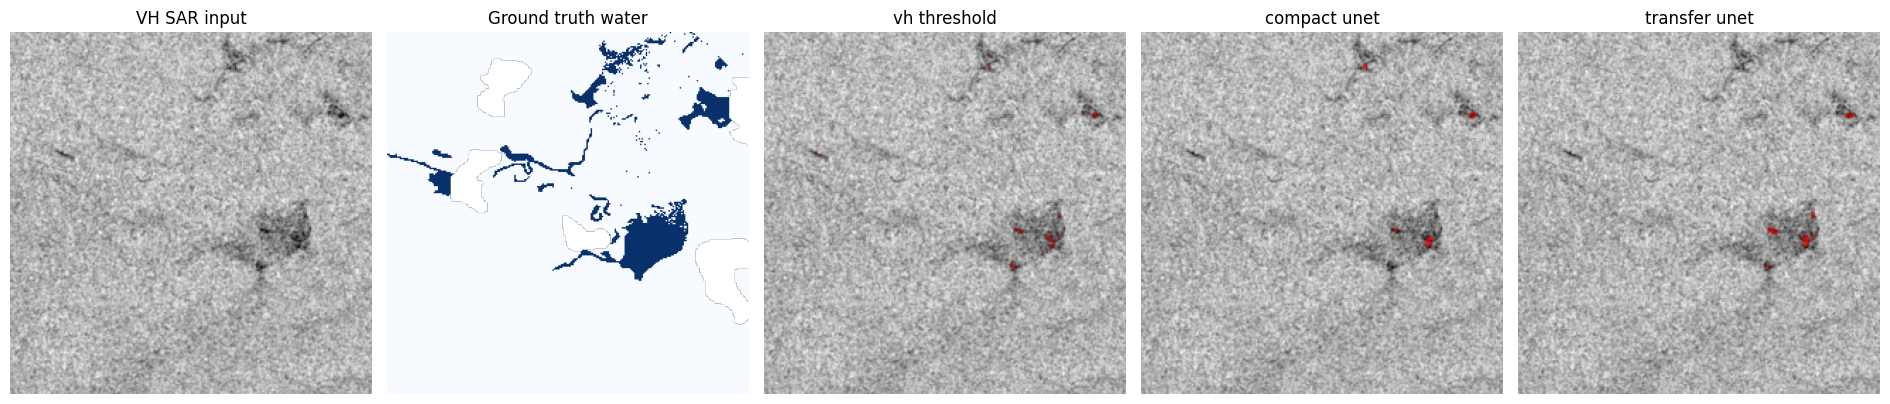

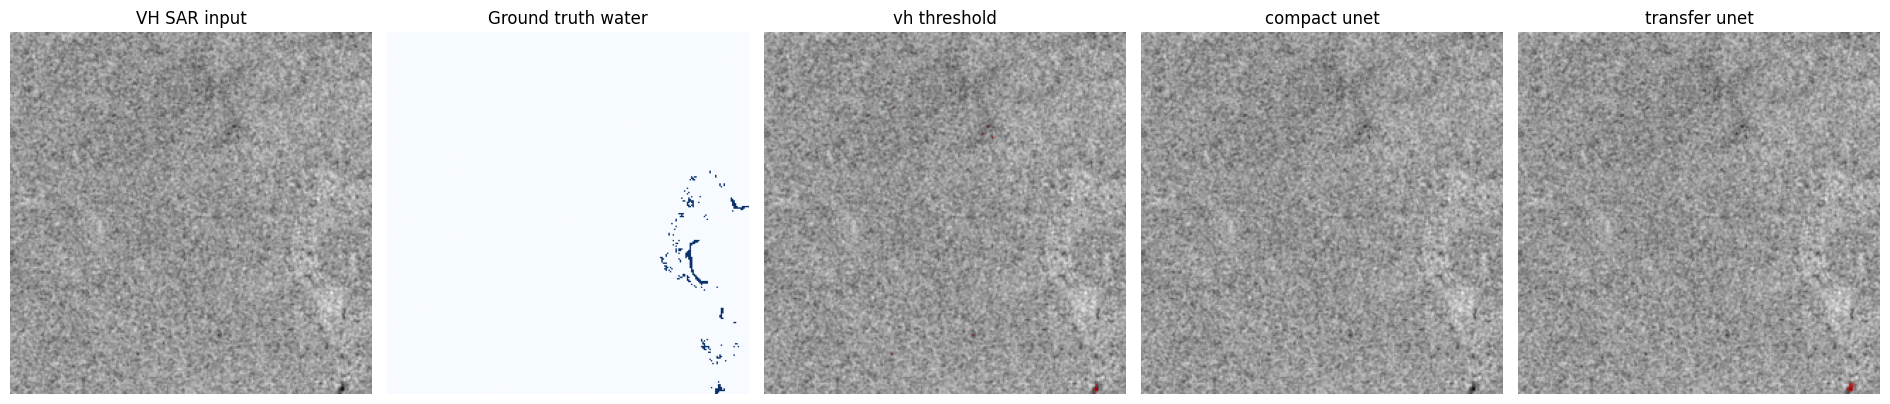

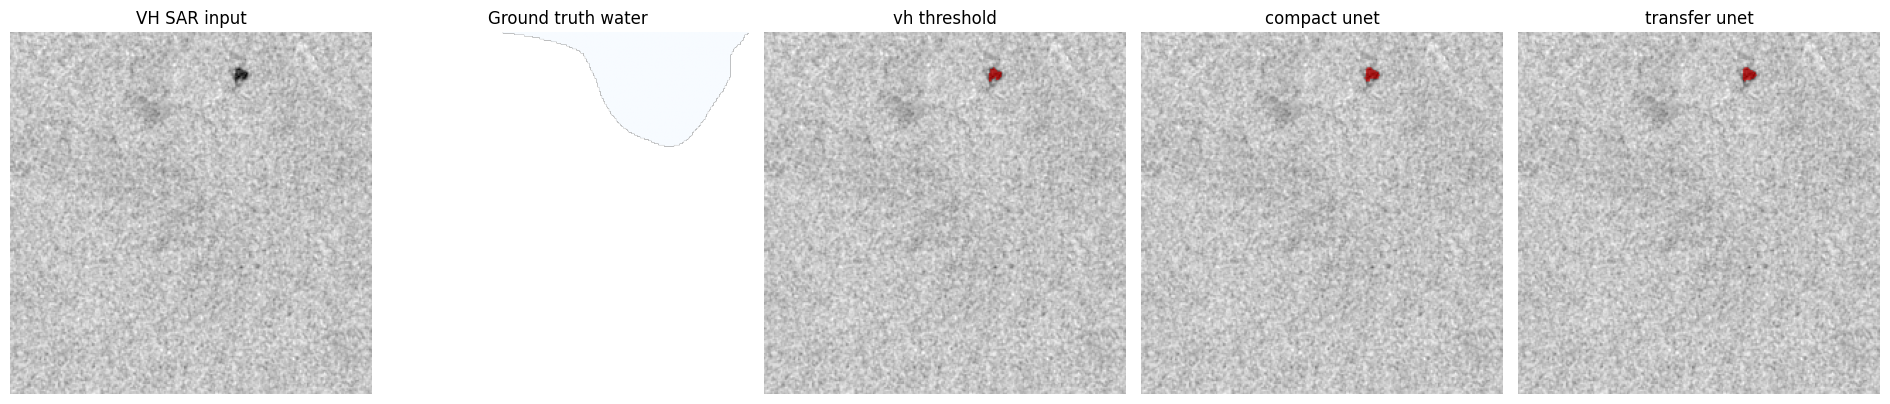

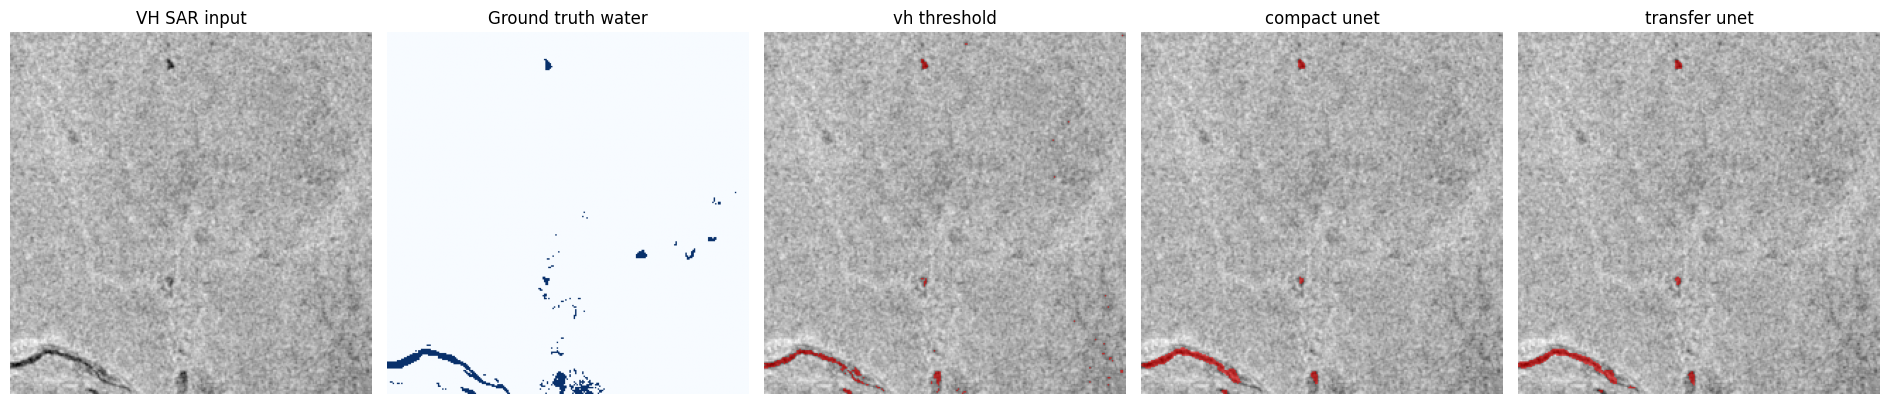

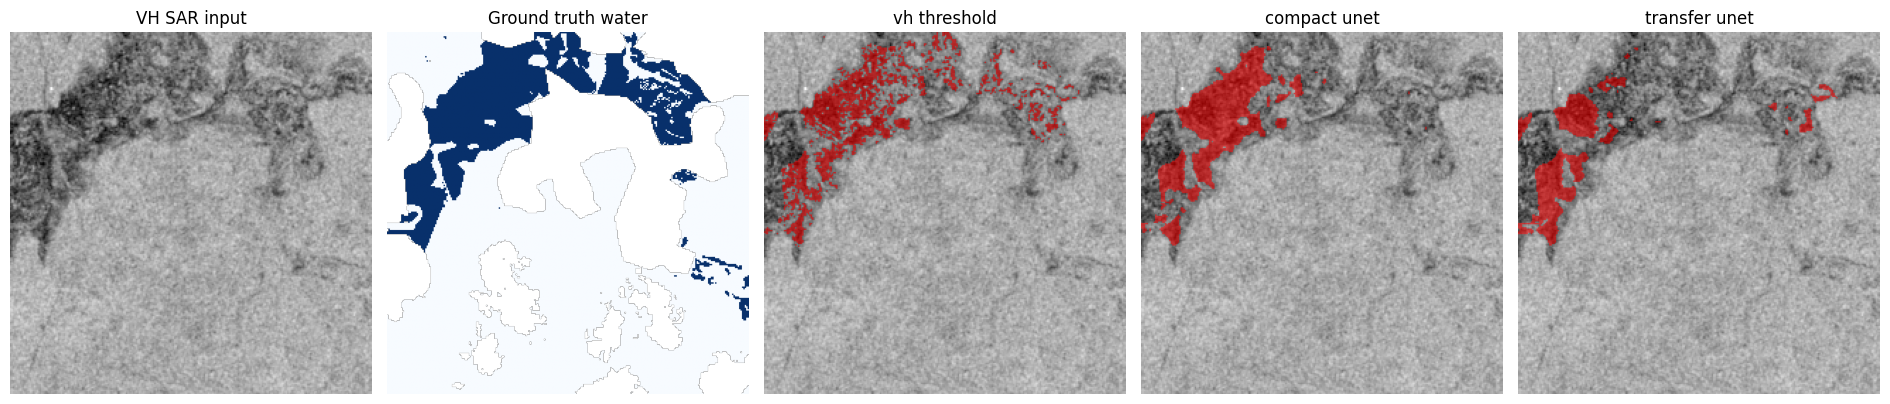

Figures and results saved to: /kaggle/working/flood_mapping/outputs


In [88]:
def predict_binary(name,x):
    if name=='vh_threshold':return (x[1].numpy()<best_threshold).astype('uint8')
    model=models[name].to(DEVICE)
    model.eval()
    with torch.no_grad(): p=torch.sigmoid(model(x[None].to(DEVICE))[0,0]).cpu().numpy()>=.5
    model.cpu();return p.astype('uint8')

n=min(5,len(test_ds))
for idx in range(n):
    x,y=test_ds[idx];gt=y.numpy();base=x[1].numpy(); valid=gt!=-1
    fig,axs=plt.subplots(1,5,figsize=(19,4))
    axs[0].imshow(base,cmap='gray');axs[0].set_title('VH SAR input')
    axs[1].imshow(np.ma.masked_where(~valid,gt),vmin=0,vmax=1,cmap='Blues');axs[1].set_title('Ground truth water')
    for j,name in enumerate(['vh_threshold','compact_unet','transfer_unet'],start=2):
        pred=predict_binary(name,x)
        axs[j].imshow(base,cmap='gray')
        rgba=np.zeros((*pred.shape,4));rgba[...,0]=1.;rgba[...,3]=.55*(pred&valid)
        axs[j].imshow(rgba);axs[j].set_title(name.replace('_',' '))
    for a in axs:a.axis('off')
    plt.tight_layout();plt.savefig(OUT/f'test_overlay_{idx+1}.png',dpi=180,bbox_inches='tight');plt.show()
print('Figures and results saved to:',OUT)

## 11. Export results for the final Overleaf paper

The `outputs` directory contains dataset tables, models, baseline tuning, train/validation curves, three confusion matrices, three classification reports, model comparison and prediction overlays. Only use files produced by **your actual notebook run** as academic evidence.


In [89]:
metadata={'dataset':'Sen1Floods11 v1.1 hand-labelled Sentinel-1','seed':SEED,'image_size':SIZE,'batch_size':BATCH_SIZE,'epochs':EPOCHS,'learning_rate':LR,'lr_schedule':'cosine','loss':'BCE+soft Dice (invalid masked)','db_range':[DB_MIN,DB_MAX],'device':DEVICE,'vh_threshold':best_threshold,'class_mapping':{'0':'non-water','1':'water','-1':'ignore'},'split_counts':{s:len(v) for s,v in splits.items()}}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
archive=shutil.make_archive(str(ROOT/'flood_mapping_results'),'zip',OUT)
print('Results ZIP:',archive)
from IPython.display import display,FileLink
display(FileLink(archive))

Results ZIP: /kaggle/working/flood_mapping/flood_mapping_results.zip


/kaggle/working/flood_mapping/flood_mapping_results.zip

### Research validity and limitations
- This dataset marks **water/non-water**, not definitively *new floodwater vs permanent water*. State the proxy clearly.
- Original split uses official chip-level partition; spatial proximity between chips can still inflate transferability estimates.
- Hyperparameters and threshold should be selected with train/validation data only; test is evaluated once.
- `LabelHand=-1` is excluded from metrics and training loss.
- Accuracy is secondary to water IoU / Dice under class imbalance.
- Transfer learning here is **ImageNet-pretrained ResNet18 encoder**, fine-tuned on 2-channel SAR. Compare fairly using identical training settings.
- Training is designed for Colab GPU; download access and dependency availability must be verified in that live environment.